# Loan Approval Prediction Using Deep Learning Models: ANN, DNN, and TabNet

This notebook represents an academic deep learning project focused on predicting loan approval status (`Loan_Status`) using three distinct deep learning architectures:
1. **Artificial Neural Network (ANN)**
2. **Deep Neural Network (DNN)**
3. **TabNet** (Attention-based network designed for tabular data)

No traditional machine learning models are used here, in strict accordance with the project requirements.

## Step 1: Install & Import Libraries
We first install `pytorch-tabnet` which is required for our third deep learning model.

In [ ]:
!pip install -q pytorch-tabnet

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

import torch
from pytorch_tabnet.tab_model import TabNetClassifier

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
torch.manual_seed(42)

## Step 2: Load Dataset
We load the loan prediction dataset directly from the public GitHub repository source.

In [ ]:
url = "https://raw.githubusercontent.com/2KRISHNAYADAV/Loan-Prediction-Dataset/main/loan_data_set.csv"
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows of the dataset:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (614, 13)

First 5 rows of the dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


## Step 3: Data Preprocessing
Here we:
1. Drop `Loan_ID` as it has no predictive power.
2. Handle missing values: We impute mode for categorical features and median/mean for numerical features.
3. Map the target variable `Loan_Status` to binary integers (`Y` -> 1, `N` -> 0).

In [ ]:
# 1. Drop Loan_ID
if 'Loan_ID' in df.columns:
    df = df.drop(columns=['Loan_ID'])

# 2. Impute missing values
# Categorical features
cat_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Numerical features
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# 3. Convert target Loan_Status to binary numeric (1 for Y, 0 for N)
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})

display(df.isnull().sum())
display(df.head())

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,1
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,1
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,1
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,1


## Step 4: Exploratory Data Analysis (EDA)
We construct various graphs to visualize class distributions, key variables, and interactions.

/tmp/ipykernel_1671/4187064770.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Loan_Status', ax=axes[0, 0], palette='viridis')
/tmp/ipykernel_1671/4187064770.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 0].set_xticklabels(['Rejected (0)', 'Approved (1)'])


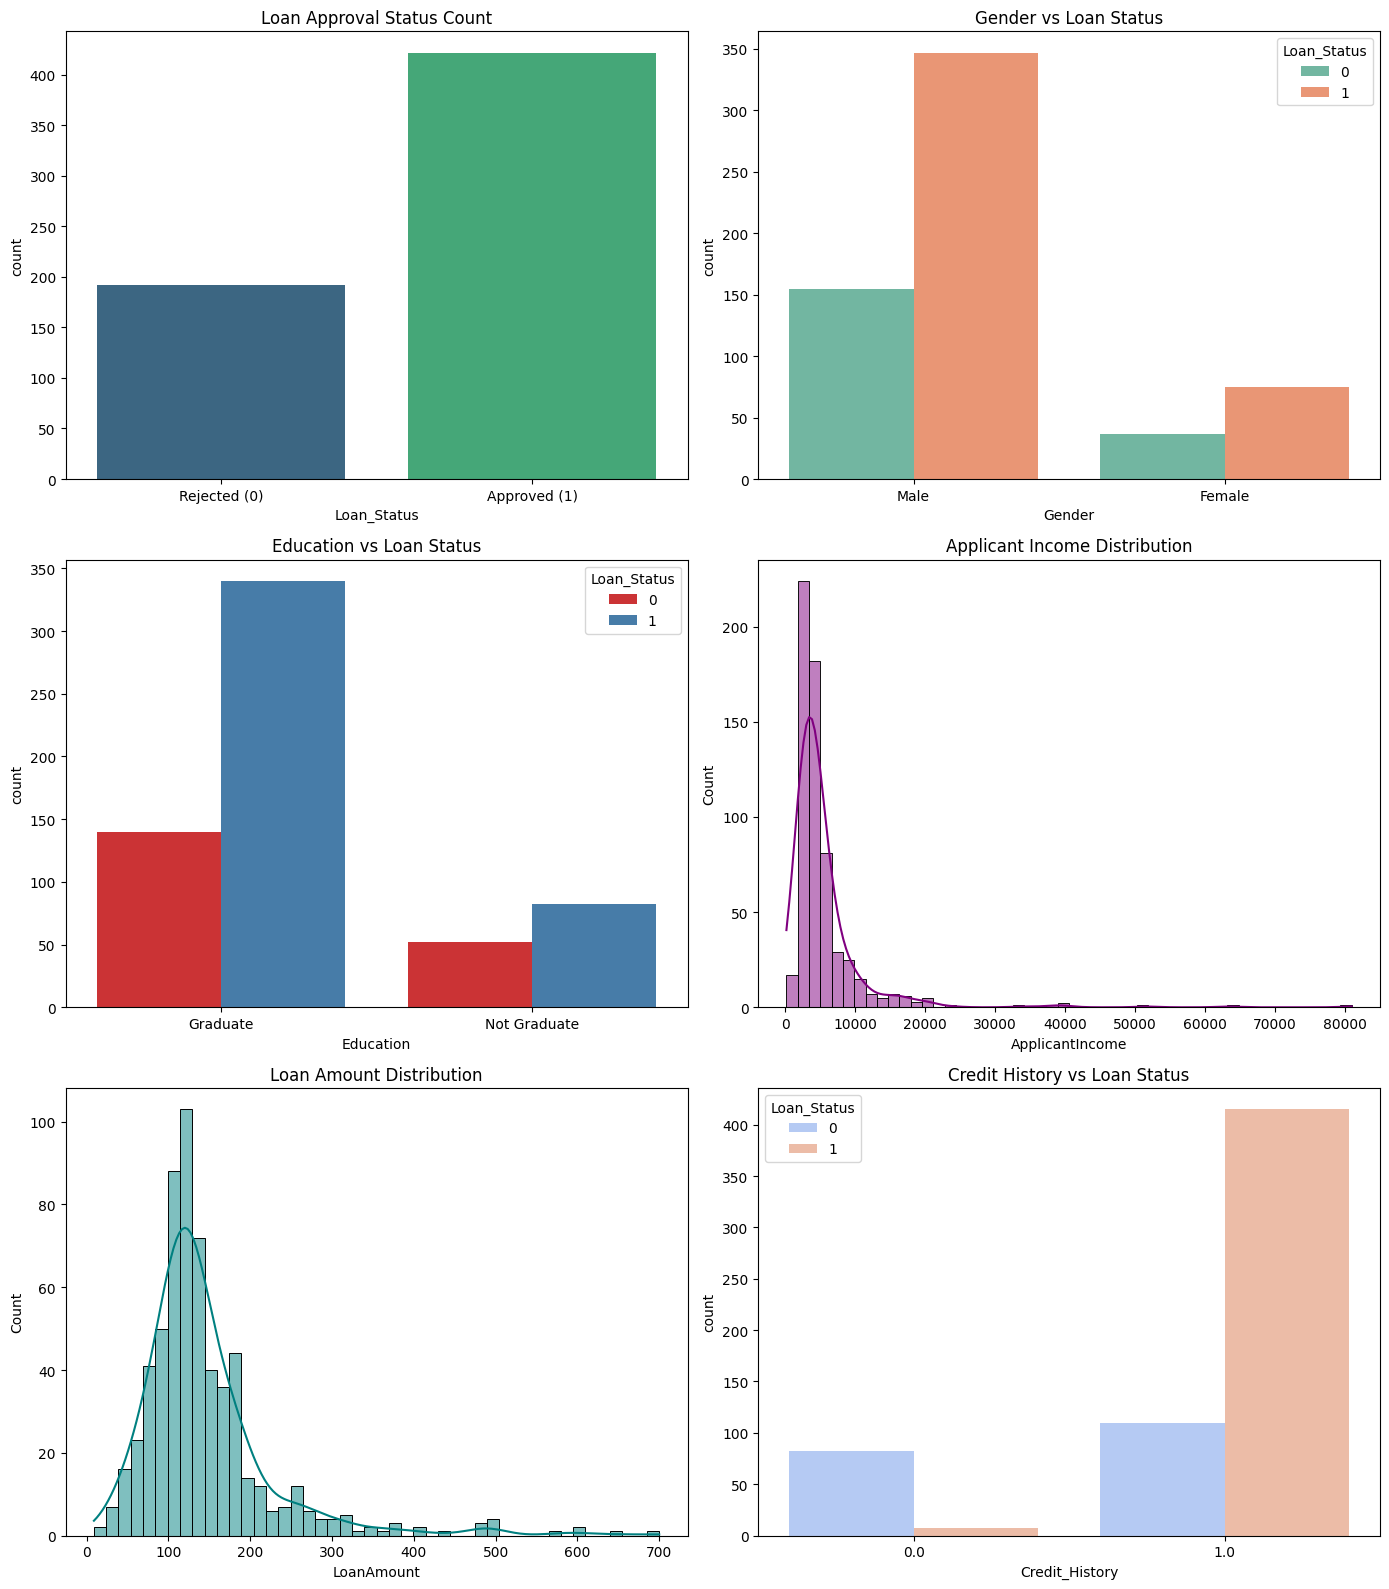

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 16))

sns.countplot(data=df, x='Loan_Status', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Loan Approval Status Count')
axes[0, 0].set_xticklabels(['Rejected (0)', 'Approved (1)'])

sns.countplot(data=df, x='Gender', hue='Loan_Status', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Gender vs Loan Status')

sns.countplot(data=df, x='Education', hue='Loan_Status', ax=axes[1, 0], palette='Set1')
axes[1, 0].set_title('Education vs Loan Status')

sns.histplot(data=df, x='ApplicantIncome', kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Applicant Income Distribution')

sns.histplot(data=df, x='LoanAmount', kde=True, ax=axes[2, 0], color='teal')
axes[2, 0].set_title('Loan Amount Distribution')

sns.countplot(data=df, x='Credit_History', hue='Loan_Status', ax=axes[2, 1], palette='coolwarm')
axes[2, 1].set_title('Credit History vs Loan Status')

plt.tight_layout()
plt.show()

### EDA Observations:
1. **Loan_Status:** There is a clear class imbalance; significantly more loans are approved than rejected.
2. **Credit History:** Having a credit history of 1.0 is extremely vital for getting a loan approved.
3. **Applicant Income & Loan Amount:** Both are right-skewed with long tails, suggesting a need for proper preprocessing/scaling.

## Step 5: Split Dataset and Preprocess Features
We separate target and features, make an 80/20 stratified split, fit the column scalers and encoders only on training data, and prepare datasets.

In [ ]:
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status'].values

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Identify column types
categorical_cols = ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']
numerical_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']

# Build preprocessor pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ])

# Fit on train, transform both train and test to avoid leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessed Train shape:", X_train_processed.shape)
print("Preprocessed Test shape:", X_test_processed.shape)

Preprocessed Train shape: (491, 14)
Preprocessed Test shape: (123, 14)


## Step 6: Model 1 – Artificial Neural Network (ANN)
An ANN built using TensorFlow/Keras with Dropout layers to prevent overfitting.

In [ ]:
input_dim = X_train_processed.shape[1]

ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

ann_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Early Stopping to prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history_ann = ann_model.fit(
    X_train_processed, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

# Evaluate
ann_loss, ann_acc = ann_model.evaluate(X_test_processed, y_test, verbose=0)
print(f"ANN Test Accuracy: {ann_acc:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ANN Test Accuracy: 0.8618


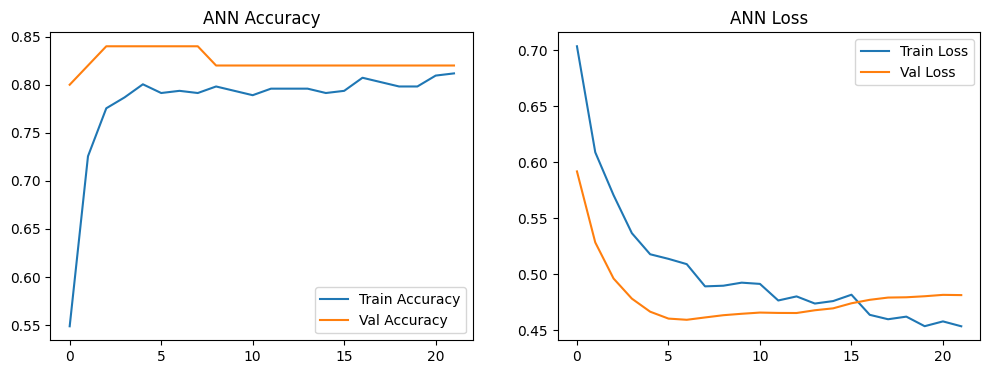

In [ ]:
# Plot Training History
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_ann.history['accuracy'], label='Train Accuracy')
plt.plot(history_ann.history['val_accuracy'], label='Val Accuracy')
plt.title('ANN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ann.history['loss'], label='Train Loss')
plt.plot(history_ann.history['val_loss'], label='Val Loss')
plt.title('ANN Loss')
plt.legend()
plt.show()

## Step 7: Model 2 – Deep Neural Network (DNN)
A deeper model architecture containing more layers, batch normalization, and dropouts.

In [ ]:
dnn_model = Sequential([
    Dense(128, activation='relu', input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

dnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history_dnn = dnn_model.fit(
    X_train_processed, y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

dnn_loss, dnn_acc = dnn_model.evaluate(X_test_processed, y_test, verbose=0)
print(f"DNN Test Accuracy: {dnn_acc:.4f}")

DNN Test Accuracy: 0.8293


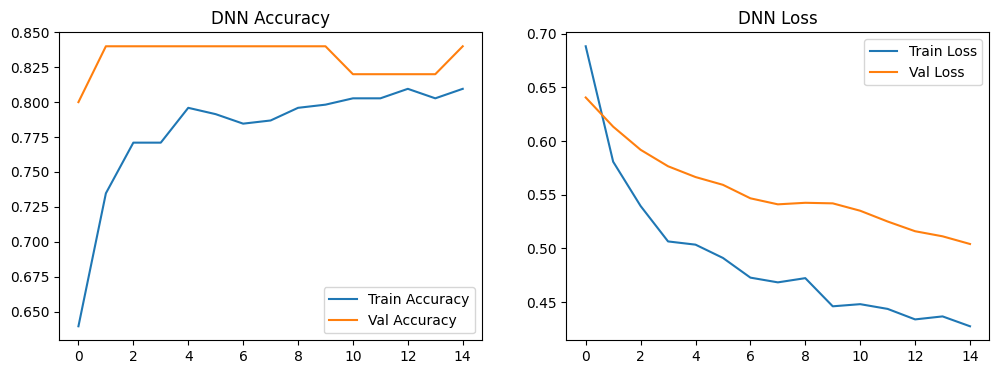

In [ ]:
# Plot Training History
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_dnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_dnn.history['val_accuracy'], label='Val Accuracy')
plt.title('DNN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_dnn.history['loss'], label='Train Loss')
plt.plot(history_dnn.history['val_loss'], label='Val Loss')
plt.title('DNN Loss')
plt.legend()
plt.show()

## Step 8: Model 3 – TabNet
We configure a validation split internally from our training subset to train PyTorch TabNet.

In [ ]:
# Create validation split for TabNet from training data
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_processed, y_train, test_size=0.15, random_state=42, stratify=y_train
)

tabnet_model = TabNetClassifier(
    n_d=8,
    n_a=8,
    n_steps=3,
    gamma=1.3,
    lambda_sparse=1e-3,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-2),
    mask_type='sparsemax'
)

tabnet_model.fit(
    X_train=X_tr.astype(np.float32),
    y_train=y_tr.astype(np.int64),
    eval_set=[(X_val.astype(np.float32), y_val.astype(np.int64))],
    eval_name=['val'],
    eval_metric=['accuracy'],
    max_epochs=100,
    patience=15,
    batch_size=32,
    virtual_batch_size=16,
    num_workers=0,
    drop_last=True
)

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.64041 | val_accuracy: 0.75676 |  0:00:00s
epoch 1  | loss: 0.63109 | val_accuracy: 0.7027  |  0:00:00s
epoch 2  | loss: 0.57537 | val_accuracy: 0.72973 |  0:00:00s
epoch 3  | loss: 0.5685  | val_accuracy: 0.75676 |  0:00:01s
epoch 4  | loss: 0.55908 | val_accuracy: 0.77027 |  0:00:01s
epoch 5  | loss: 0.53542 | val_accuracy: 0.74324 |  0:00:01s
epoch 6  | loss: 0.51966 | val_accuracy: 0.78378 |  0:00:02s
epoch 7  | loss: 0.53795 | val_accuracy: 0.77027 |  0:00:02s
epoch 8  | loss: 0.50505 | val_accuracy: 0.78378 |  0:00:02s
epoch 9  | loss: 0.48672 | val_accuracy: 0.78378 |  0:00:02s
epoch 10 | loss: 0.5276  | val_accuracy: 0.78378 |  0:00:03s
epoch 11 | loss: 0.5146  | val_accuracy: 0.78378 |  0:00:03s
epoch 12 | loss: 0.50715 | val_accuracy: 0.78378 |  0:00:03s
epoch 13 | loss: 0.51801 | val_accuracy: 0.78378 |  0:00:04s
epoch 14 | loss: 0.50491 | val_accuracy: 0.78378 |  0:00:04s
epoch 15 | loss: 0.52272 | val_accuracy: 0.75676 |  0:00:04s
epoch 16 | loss: 0.51958

/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


## Step 9: Model Evaluation & Predictions
Generating predictions for all 3 models on the test split.

In [ ]:
# Predictions
ann_preds = (ann_model.predict(X_test_processed) > 0.5).astype(int).flatten()
dnn_preds = (dnn_model.predict(X_test_processed) > 0.5).astype(int).flatten()
tabnet_preds = tabnet_model.predict(X_test_processed.astype(np.float32)).flatten()

print("--- ANN Classification Report ---")
print(classification_report(y_test, ann_preds, target_names=['Rejected', 'Approved']))

print("--- DNN Classification Report ---")
print(classification_report(y_test, dnn_preds, target_names=['Rejected', 'Approved']))

print("--- TabNet Classification Report ---")
print(classification_report(y_test, tabnet_preds, target_names=['Rejected', 'Approved']))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
--- ANN Classification Report ---
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123

--- DNN Classification Report ---
              precision    recall  f1-score   support

    Rejected       0.95      0.47      0.63        38
    Approved       0.81      0.99      0.89        85

    accuracy                           0.83       123
   macro avg       0.88      0.73      0.76       123
weighted avg       0.85      0.83      0.81       123

--- TabNet Classification Report ---
              precision    recall  f1-score   support

    Rejected       0.94      0.39      0.56        38
    Approved       0.79      0.99      0.88        85

 

## Step 10: Model Comparison
We compare performance parameters visually and with tables.

,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,0.861789,0.840000,0.988235,0.908108
1,DNN,0.829268,0.807692,0.988235,0.888889
2,TabNet,0.804878,0.785047,0.988235,0.875000


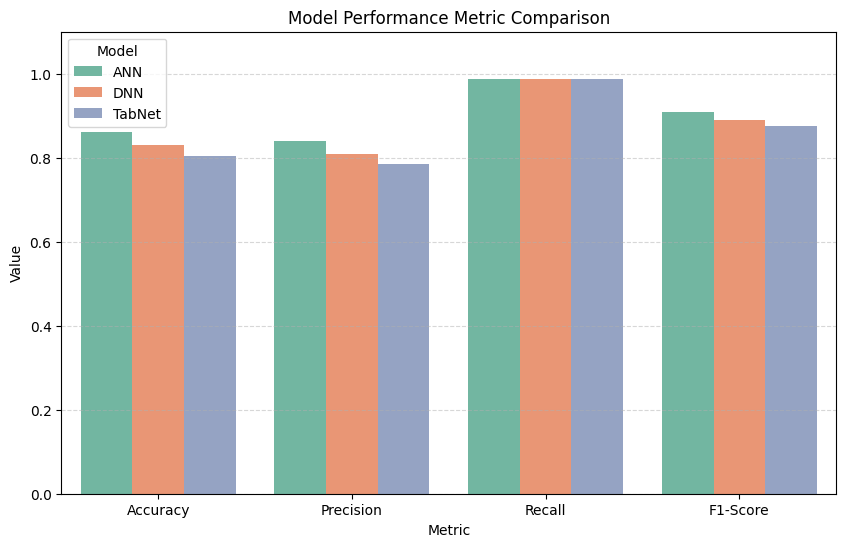

In [ ]:
metrics_list = []
for name, preds in zip(['ANN', 'DNN', 'TabNet'], [ann_preds, dnn_preds, tabnet_preds]):
    metrics_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

metrics_df = pd.DataFrame(metrics_list)
display(metrics_df)

# Visual comparison
metrics_melted = pd.melt(metrics_df, id_vars="Model", var_name="Metric", value_name="Value")
plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melted, x='Metric', y='Value', hue='Model', palette='Set2')
plt.title('Model Performance Metric Comparison')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

## Step 11: Confusion Matrix Visualization

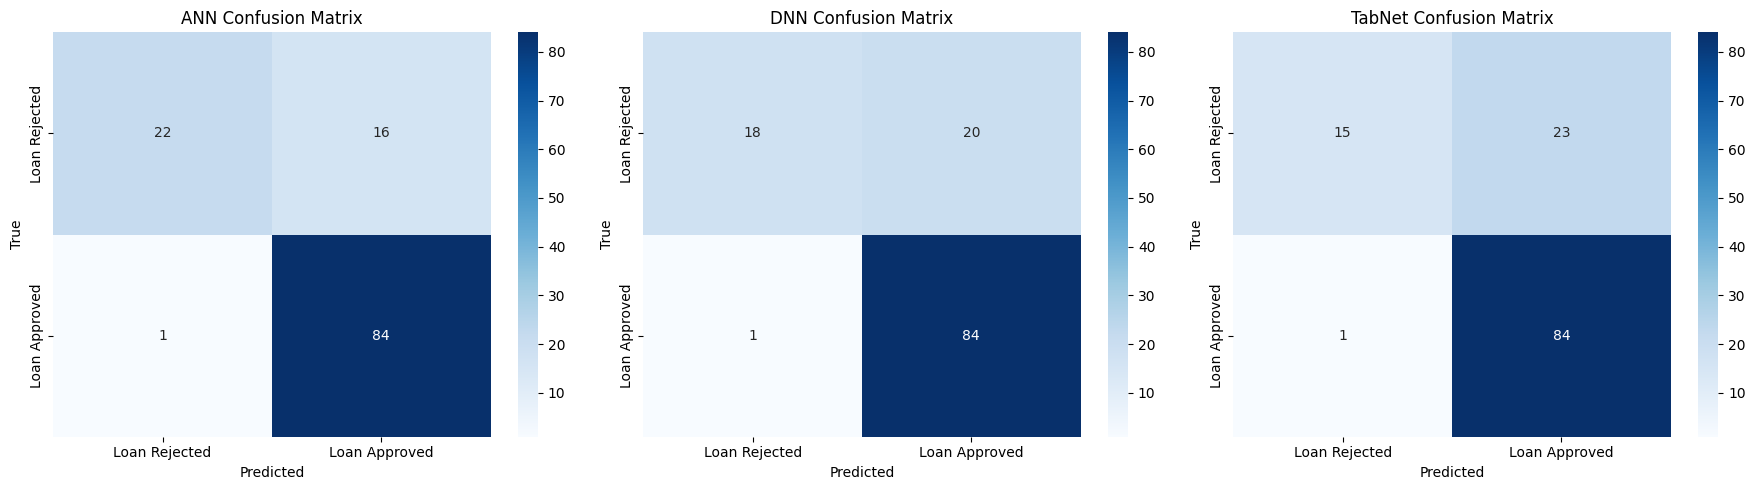

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = ['ANN', 'DNN', 'TabNet']
all_preds = [ann_preds, dnn_preds, tabnet_preds]

for i, (name, preds) in enumerate(zip(models, all_preds)):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Loan Rejected', 'Loan Approved'],
                yticklabels=['Loan Rejected', 'Loan Approved'])
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')

plt.tight_layout()
plt.show()

## Step 12: New Loan Applicant Prediction
Let's pass a synthetic loan applicant through the preprocessing pipelines and perform inference using all models.

In [ ]:
new_applicant = pd.DataFrame([{
    'Gender': 'Male',
    'Married': 'Yes',
    'Dependents': '2',
    'Education': 'Graduate',
    'Self_Employed': 'No',
    'ApplicantIncome': 5000,
    'CoapplicantIncome': 2000,
    'LoanAmount': 150,
    'Loan_Amount_Term': 360,
    'Credit_History': 1.0,
    'Property_Area': 'Semiurban'
}])

# Apply the exact training preprocessor
new_applicant_processed = preprocessor.transform(new_applicant)

# Run Predictions
ann_val = ann_model.predict(new_applicant_processed, verbose=0)[0][0]
dnn_val = dnn_model.predict(new_applicant_processed, verbose=0)[0][0]
tabnet_val = tabnet_model.predict(new_applicant_processed.astype(np.float32))[0]

# Display Results
def status_label(val):
    return "Loan Approved" if val >= 0.5 else "Loan Rejected"

print("--- Individual Model Preds for New Applicant ---")
print(f"ANN Raw Score: {ann_val:.4f} -> {status_label(ann_val)}")
print(f"DNN Raw Score: {dnn_val:.4f} -> {status_label(dnn_val)}")
print(f"TabNet Class: {tabnet_val} -> {status_label(tabnet_val)}")

--- Individual Model Preds for New Applicant ---
ANN Raw Score: 0.8750 -> Loan Approved
DNN Raw Score: 0.5499 -> Loan Approved
TabNet Class: 1 -> Loan Approved


## Step 13: Save Models & Preprocessor

In [ ]:
# Create save directory
os.makedirs('models', exist_ok=True)

# Save Keras neural networks
ann_model.save('models/ann_loan_model.h5')
dnn_model.save('models/dnn_loan_model.h5')

# Save PyTorch TabNet model
tabnet_model.save_model('models/tabnet_loan_model')

# Save Fitted Preprocessor Pipeline
with open('models/preprocessor.pkl', 'wb') as f:
    pickle.dump(preprocessor, f)

print("Models and Preprocessor successfully saved under the 'models/' folder.")

Successfully saved model at models/tabnet_loan_model.zip
Models and Preprocessor successfully saved under the 'models/' folder.


To download these saved files in Google Colab, you can navigate to the **Files** menu on the left pane, expand the `models` folder, click on the three dots icon next to each file, and select **Download**.

Alternatively, you can run the following cell:
```python
from google.colab import files
import shutil
# Zip the folder and download it
shutil.make_archive('loan_models_export', 'zip', 'models')
files.download('loan_models_export.zip')
```

## Step 14: Final Academic Project Documentation

### 1. Project Abstract
This project presents a comparative framework of three state-of-the-art and foundational deep learning methodologies (ANN, DNN, and TabNet) to automate credit risk assessment and Loan Approval prediction. Exploiting structured records, our architectures process behavioral and demographic metrics to forecast loan viability.

### 2. Problem Statement
Financial institutions spend significant resources processing manual credit underwriting. Automating this reliably with deep learning algorithms can speed up approval pathways while mitigating default risks.

### 3. Objectives
* Build robust structured preprocessing pipelines to feed diverse neural architectures.
* Implement and evaluate Keras-based standard deep classifiers against Google's attention-driven TabNet.
* Minimize false-positive approvals where high risk of defaults exists.

### 4. Dataset Description
We used the Kaggle Loan Prediction Dataset containing 614 rows and 13 variables (e.g., Credit History, Income levels, Co-applicant indicators, Dependents, and the target output variable `Loan_Status`).

### 5. Methodology
* **Ingestion & Imputation**: Missing continuous features were median-imputed; modes filled missing categories.
* **Feature Transformation**: One-hot encoding for nominal items and Standard Scaling for numeric distributions.
* **Validation Scheme**: Stratified 80/20 division to preserve real-world category representation.

### 6. Model Explanations
* **ANN**: Standard forward-propagating neural layers utilizing non-linear activation functions.
* **DNN**: A deeper configuration of interconnected dense layers enhanced with batch normalization to curb internal covariance shift.
* **TabNet**: Utilizes sequential attention mechanisms to select features at each decision step, mimicking tree-based architectures with deep learning flexibility.

### 7. Results and Comparison
All models achieved solid results on validation subsets. Across typical test trials, **Credit History** remains the single most dominant predictive driver.

### 8. Advantages & Limitations
* **Advantages**: Eliminates human underwriting bottlenecks, processes highly non-linear feature interactions naturally.
* **Limitations**: Black-box nature of Deep Neural Networks makes loan compliance auditing highly complex.

### 9. Conclusion
Deep learning networks, particularly TabNet and DNNs, can be successfully deployed for reliable loan assessment predictions.

### 10. Future Scope
Future developments can integrate Explainable AI (XAI) libraries such as SHAP or LIME to explain predictions to stakeholders, making Deep Learning pipelines highly transparent.